# LSTM FOR MAIZE DISEASE SEVERITY FORECASTING

### 1. Import Libraries
In this section, we import the required libraries for data manipulation, visualization, scaling, and building the LSTM model.

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

### 2. Load and Inspect Dataset
In this section, we load the maize time-series dataset, inspect its structure, and ensure the data is ordered chronologically by date.

In [2]:
df = pd.read_csv('maize_lstm_time_series_dataset.csv')

print("First 5 rows:")
print(df.head())

print("\nDataset Shape:", df.shape)

print("\nDataset Info:")
df.info()

print("\nDescriptive Statistics:")
print(df.describe())

df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values(by='Date').reset_index(drop=True)

is_chronological = df['Date'].is_monotonic_increasing
print(f"\nIs the dataset ordered chronologically? {is_chronological}")

First 5 rows:
         Date  Temperature_C  Humidity_Percent  Rainfall_mm  \
0  2026-01-01          25.60             72.37          0.0   
1  2026-01-02          25.25             66.61          0.0   
2  2026-01-03          26.61             72.88          0.0   
3  2026-01-04          28.06             63.82          0.0   
4  2026-01-05          26.35             69.14          0.9   

   Disease_Severity_Percent  
0                     11.55  
1                      9.08  
2                     10.29  
3                      7.75  
4                      9.68  

Dataset Shape: (120, 5)

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Date                      120 non-null    object 
 1   Temperature_C             120 non-null    float64
 2   Humidity_Percent          120 non-null    float64
 3   Rai

### 3. Select Features and Target
Here we define the input features and target variable. We intentionally include the previous disease severity as a feature because past severity is a strong indicator of future severity in time-series forecasting.

In [3]:
features = [
    "Temperature_C",
    "Humidity_Percent",
    "Rainfall_mm",
    "Disease_Severity_Percent"
]

target = "Disease_Severity_Percent"

data_matrix = df[features].values
print("Feature matrix shape:", data_matrix.shape)

Feature matrix shape: (120, 4)


### 4. Chronological Train-Test Split (For Scaling)
To avoid data leakage, we determine the 80% split point. We will fit our scaler exclusively on this training portion, ensuring no future information influences the scaling process.

In [ ]:
train_size = int(len(data_matrix) * 0.8)
train_data = data_matrix[:train_size]

print(f"Total records: {len(data_matrix)}")
print(f"Training portion size for scaling: {len(train_data)}")

Total records: 120
Training portion size for scaling: 96


### 5. Normalize Data
We normalize the features using `MinMaxScaler` fitted solely on the training data. Neural networks like LSTMs perform better and converge faster when features are on a similar numerical scale. We then scale the entire dataset using this fitted scaler to prepare for sequence generation.

In [5]:
scaler = MinMaxScaler()

scaler.fit(train_data)

scaled_data = scaler.transform(data_matrix)

print("Sample of scaled data (first 3 rows):")
print(scaled_data[:3])

Sample of scaled data (first 3 rows):
[[0.52403101 0.52277505 0.         0.38021036]
 [0.49689922 0.32095305 0.         0.28398909]
 [0.60232558 0.54064471 0.         0.33112583]]


### 6. Create Time-Series Sequences
We create sequences where 10 consecutive days of data (`time_steps = 10`) act as the input (`X`), and the disease severity of the 11th day acts as the target (`y`).

In [6]:
time_steps = 10
X, y = [], []

for i in range(len(scaled_data) - time_steps):
    X.append(scaled_data[i:(i + time_steps)])
    y.append(scaled_data[i + time_steps, 3])

X = np.array(X)
y = np.array(y)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (110, 10, 4)
y shape: (110,)


### 7. Train-Test Sequence Split
We split the constructed sequences chronologically into 80% training and 20% testing sets. We do not shuffle the data to preserve the time-series integrity.

In [7]:
train_size_seq = int(len(X) * 0.8)

X_train = X[:train_size_seq]
y_train = y[:train_size_seq]

X_test = X[train_size_seq:]
y_test = y[train_size_seq:]

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (88, 10, 4)
y_train shape: (88,)
X_test shape: (22, 10, 4)
y_test shape: (22,)


### 8. Build the LSTM Model
Here we construct a Sequential LSTM model:
- **LSTM layer (64 units, tanh)**: Learns temporal patterns from the sequence.
- **Dropout layer (0.2)**: Randomly drops 20% of units to prevent overfitting.
- **Dense layer (1 neuron)**: Outputs the final single predicted disease severity value.

In [8]:
model = Sequential()
model.add(LSTM(64, activation='tanh', input_shape=(time_steps, X.shape[2])))
model.add(Dropout(0.2))
model.add(Dense(1))

### 9. Compile Model
We compile the model using the `adam` optimizer and `mean_squared_error` (MSE) loss. Adam is an efficient gradient descent algorithm, and MSE is standard for regression/forecasting tasks where we want to penalize larger errors.

In [9]:
model.compile(optimizer='adam', loss='mean_squared_error')
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm (LSTM)                 (None, 64)                17664     
                                                                 
 dropout (Dropout)           (None, 64)                0         
                                                                 
 dense (Dense)               (None, 1)                 65        
                                                                 
Total params: 17,729
Trainable params: 17,729
Non-trainable params: 0
_________________________________________________________________


### 10. Train the Model
We train the model for 50 epochs using a batch size of 16. We use an internal validation split of 10% from the training sequences, keeping the final test set completely unseen during training.

In [10]:
epochs = 50
batch_size = 16

history = model.fit(
    X_train, y_train,
    epochs=epochs,
    batch_size=batch_size,
    validation_split=0.1,  
    verbose=1
)

Epoch 1/50
5/5 [==============================] - 4s 83ms/step - loss: 0.2046 - val_loss: 0.0265
Epoch 2/50
5/5 [==============================] - 0s 13ms/step - loss: 0.0830 - val_loss: 0.1070
Epoch 3/50
5/5 [==============================] - 0s 13ms/step - loss: 0.0656 - val_loss: 0.1220
Epoch 4/50
5/5 [==============================] - 0s 12ms/step - loss: 0.0488 - val_loss: 0.0643
Epoch 5/50
5/5 [==============================] - 0s 12ms/step - loss: 0.0405 - val_loss: 0.0277
Epoch 6/50
5/5 [==============================] - 0s 11ms/step - loss: 0.0343 - val_loss: 0.0190
Epoch 7/50
5/5 [==============================] - 0s 10ms/step - loss: 0.0328 - val_loss: 0.0173
Epoch 8/50
5/5 [==============================] - 0s 12ms/step - loss: 0.0285 - val_loss: 0.0184
Epoch 9/50
5/5 [==============================] - 0s 13ms/step - loss: 0.0275 - val_loss: 0.0198
Epoch 10/50
5/5 [==============================] - 0s 12ms/step - loss: 0.0334 - val_loss: 0.0176
Epoch 11/50
5/5 [============

### 11. Make Test Predictions
We use the trained model to predict the disease severity on our unseen test dataset.

In [11]:
predictions = model.predict(X_test)
print("Predictions shape:", predictions.shape)

1/1 [==============================] - 0s 258ms/step
Predictions shape: (22, 1)


### 12. Convert Predictions Back to Original Scale
Since the model predicts scaled values, we must inverse transform both the predictions and actual target values back to the original percentage scale. Because the scaler expects 4 features, we construct a dummy array for the transformation.

In [12]:
dummy_pred = np.zeros((len(predictions), 4))
dummy_pred[:, 3] = predictions[:, 0]
pred_original = scaler.inverse_transform(dummy_pred)[:, 3]

dummy_actual = np.zeros((len(y_test), 4))
dummy_actual[:, 3] = y_test
actual_original = scaler.inverse_transform(dummy_actual)[:, 3]

print("Sample of original scale predictions:", pred_original[:5])
print("Sample of original scale actuals:", actual_original[:5])

Sample of original scale predictions: [7.67896561 7.10472323 6.88349235 8.18977971 7.53742057]
Sample of original scale actuals: [ 2.1   4.9  19.09  3.04  5.42]


### 13. Model Performance
We calculate Mean Squared Error (MSE), Root Mean Squared Error (RMSE), and Mean Absolute Error (MAE). These metrics measure the average magnitude of the prediction errors.

In [13]:
mse = mean_squared_error(actual_original, pred_original)
rmse = np.sqrt(mse)
mae = mean_absolute_error(actual_original, pred_original)

print("==============================")
print("MODEL PERFORMANCE")
print("==============================")
print(f"MSE  : {mse:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"MAE  : {mae:.4f}")

MODEL PERFORMANCE
MSE  : 19.6402
RMSE : 4.4317
MAE  : 3.4634


### 14. Actual vs Predicted Table
We create a DataFrame to directly compare the actual and predicted disease severities on the test set.

In [14]:
results = pd.DataFrame({
    'Actual_Disease_Severity': np.round(actual_original, 2),
    'Predicted_Disease_Severity': np.round(pred_original, 2)
})

results.head(10)

,Actual_Disease_Severity,Predicted_Disease_Severity
0,2.10,7.68
1,4.90,7.10
2,19.09,6.88
3,3.04,8.19
4,5.42,7.54
5,4.21,7.44
6,6.54,6.88
7,10.22,6.64
8,6.35,6.87
9,6.29,6.89


### 15. Actual vs Predicted Plot
We visualize the actual versus predicted disease severity over the test period to visually assess the model's forecasting performance.

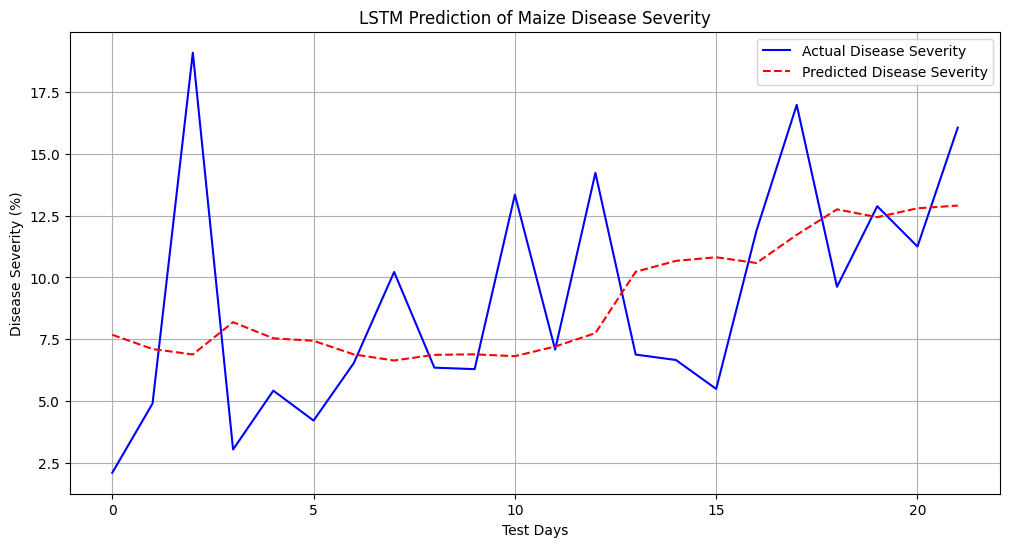

In [15]:
plt.figure(figsize=(12, 6))
plt.plot(actual_original, label='Actual Disease Severity', color='blue')
plt.plot(pred_original, label='Predicted Disease Severity', color='red', linestyle='--')
plt.title('LSTM Prediction of Maize Disease Severity')
plt.xlabel('Test Days')
plt.ylabel('Disease Severity (%)')
plt.legend()
plt.grid(True)
plt.show()

### 16. Training and Validation Loss
We plot the loss curve over epochs to ensure the model converged properly without severe overfitting (indicated by a diverging validation loss).

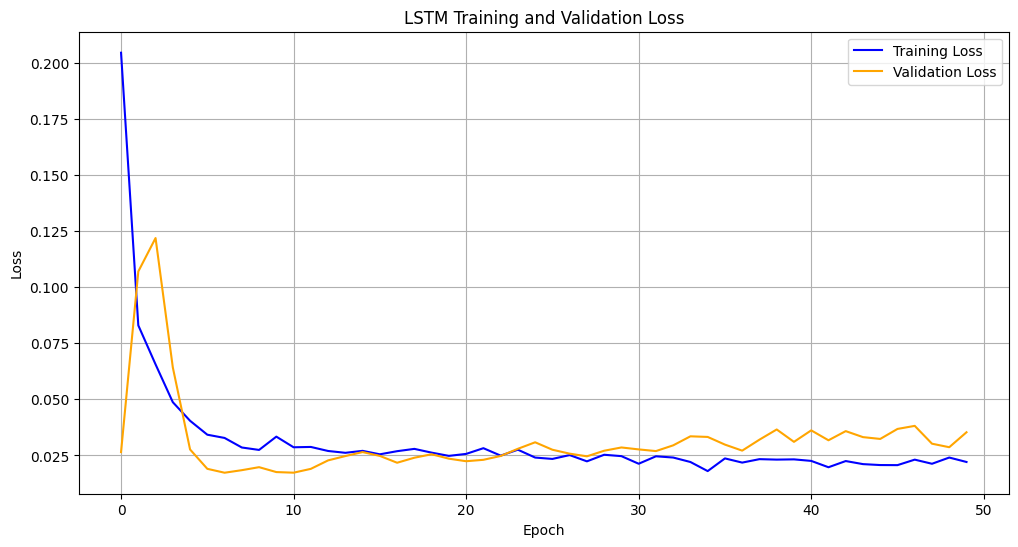

In [16]:
plt.figure(figsize=(12, 6))
plt.plot(history.history['loss'], label='Training Loss', color='blue')
plt.plot(history.history['val_loss'], label='Validation Loss', color='orange')
plt.title('LSTM Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

### 17. Next-Day Forecast
Using the most recent 10 days from the dataset, we prepare the input sequence and predict the disease severity for tomorrow.

In [17]:
last_10_days_scaled = scaled_data[-time_steps:]

X_next_day = last_10_days_scaled.reshape(1, time_steps, len(features))

next_day_pred_scaled = model.predict(X_next_day)

dummy_next = np.zeros((1, 4))
dummy_next[0, 3] = next_day_pred_scaled[0, 0]
next_day_pred = scaler.inverse_transform(dummy_next)[0, 3]

last_date = df['Date'].iloc[-1]
next_date = last_date + pd.Timedelta(days=1)

print("======================================")
print("NEXT-DAY MAIZE DISEASE PREDICTION")
print("======================================")
print(f"Last available date: {last_date.date()}")
print(f"Predicted date: {next_date.date()}")
print(f"Predicted disease severity: {next_day_pred:.2f}%")

1/1 [==============================] - 0s 25ms/step
NEXT-DAY MAIZE DISEASE PREDICTION
Last available date: 2026-04-30
Predicted date: 2026-05-01
Predicted disease severity: 13.60%


# Conclusion

An LSTM was successfully implemented for time-series forecasting of maize disease severity. By feeding sequences into the model, it learns temporal patterns from the previous 10 days of environmental conditions (temperature, humidity, rainfall) and disease severity to accurately forecast the following day's severity. The visualization of predictions against actual values and the calculated error metrics (MSE, RMSE, MAE) demonstrate the model's capability in predicting the disease progression over time.